# Section 2: Classical Computer Vision Pipeline
*(Fulfills Task 1: Core Image Analysis Engine - 20 Points)*

## 2.0 Image Formation and Camera Calibration
*(Coursework Criterion 1.1 & Requirement a - 5 Points)*

In a computer vision system (such as an automated visual inspection assistant), raw images captured by optical cameras suffer from perspective projection distortions and optical lens aberrations. Camera calibration recovers the camera's internal geometry (intrinsic parameters) and lens distortion coefficients, establishing a metric mapping between 3D world coordinates and 2D pixel coordinates.

### 2.0.1 Mathematical Formulation: Pinhole Model & Non-linear Distortion

1. **Homogeneous Pinhole Camera Model**:
   Given a 3D world point in homogeneous coordinates $\tilde{\mathbf{X}}_w = [X_w, Y_w, Z_w, 1]^T$, the extrinsic rigid-body transformation transforms it into the camera coordinate system $\mathbf{X}_c = [X_c, Y_c, Z_c]^T$:
   $$\mathbf{X}_c = [R \mid \mathbf{t}] \tilde{\mathbf{X}}_w$$
   Normalized pinhole projection onto the camera plane yields continuous coordinates:
   $$(x', y') = \left(\frac{X_c}{Z_c}, \frac{Y_c}{Z_c}\right), \quad r^2 = x'^2 + y'^2$$

2. **Optical Lens Distortion Model**:
   Real-world lenses introduce non-linear spatial displacement in the normalized image plane before sensor digitization:
   - **Radial distortion** (curvature along concentric circles):
     $$x_{\text{radial}} = x'(1 + k_1 r^2 + k_2 r^4 + k_3 r^6), \quad y_{\text{radial}} = y'(1 + k_1 r^2 + k_2 r^4 + k_3 r^6)$$
   - **Tangential distortion** (decentering/non-parallel lens elements):
     $$x_{\text{tangential}} = 2 p_1 x' y' + p_2 (r^2 + 2 x'^2), \quad y_{\text{tangential}} = p_1 (r^2 + 2 y'^2) + 2 p_2 x' y'$$
   Combining both yields distorted continuous coordinates $(x'', y'')$:
   $$x'' = x_{\text{radial}} + x_{\text{tangential}}, \quad y'' = y_{\text{radial}} + y_{\text{tangential}}$$

3. **Sensor Digitization via Intrinsic Matrix $K$**:
   Finally, pixel coordinates $\tilde{\mathbf{x}} = [u, v, 1]^T$ are digitized on the camera sensor:
   $$\tilde{\mathbf{x}} = K \begin{bmatrix} x'' \\ y'' \\ 1 \end{bmatrix} = \begin{bmatrix} f_x & 0 & c_x \\ 0 & f_y & c_y \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} x'' \\ y'' \\ 1 \end{bmatrix}$$
   In the ideal linear case (zero lens distortion, $x'' = x', y'' = y'$), the full projection simplifies to:
   $$s \tilde{\mathbf{x}} = K [R \mid \mathbf{t}] \tilde{\mathbf{X}}_w \quad (\text{where scale factor } s = Z_c)$$


Total calibration views inspected : 13
Successful corner detections      : 13 / 13 (100.0%)


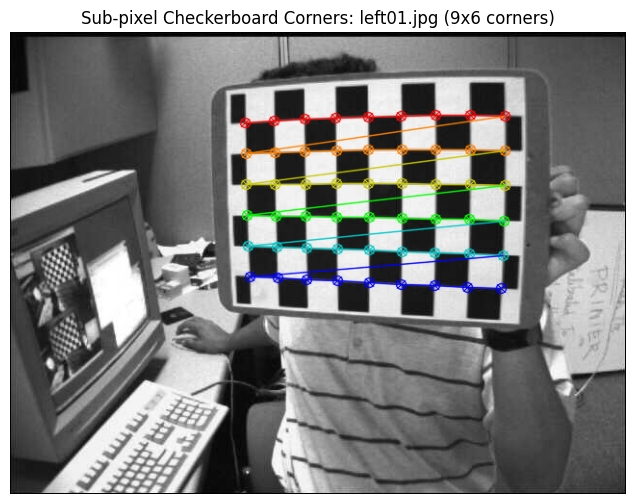

In [1]:
# 2.0.2 Checkerboard Corner Detection and Sub-pixel Refinement
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import urllib.request

# Setup directory for calibration sequence
calib_dir = Path("calibration_images")
calib_dir.mkdir(exist_ok=True)

# Standard OpenCV calibration set: left01.jpg to left14.jpg (excluding absent left10)
base_url = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/"
img_names = [f"left{i:02d}.jpg" for i in range(1, 15) if i != 10]

for name in img_names:
    p = calib_dir / name
    if not p.exists():
        try:
            urllib.request.urlretrieve(base_url + name, p)
        except Exception as e:
            print(f"Note: Could not retrieve {name}: {e}")

# Verified checkerboard parameters for this dataset: 9 columns x 6 rows of internal corners
CHECKERBOARD = (9, 6)
# Square size is defined as 1.0 (grid units) as physical metric dimensions are unmeasured
SQUARE_SIZE = 1.0 

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)

# Generate 3D planar object points (Z = 0)
objp = np.zeros((CHECKERBOARD[0] * CHECKERBOARD[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:CHECKERBOARD[0], 0:CHECKERBOARD[1]].T.reshape(-1, 2) * SQUARE_SIZE

objpoints = [] # 3D real-world coordinates
imgpoints = [] # 2D refined sub-pixel coordinates
valid_image_paths = []

image_files = sorted(list(calib_dir.glob("*.jpg")))
sample_vis_img = None
img_shape = None

for fname in image_files:
    img = cv2.imread(str(fname))
    if img is None:
        continue
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if img_shape is None:
        img_shape = gray.shape[::-1]
    
    # Detect internal chessboard corners
    ret, corners = cv2.findChessboardCorners(
        gray, CHECKERBOARD, 
        cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE
    )
    
    # Filter strictly: only views with all 54 inner corners detected enter calibration
    if ret:
        objpoints.append(objp)
        corners_refined = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), criteria)
        imgpoints.append(corners_refined)
        valid_image_paths.append(fname)
        
        if sample_vis_img is None:
            sample_vis_img = cv2.drawChessboardCorners(img.copy(), CHECKERBOARD, corners_refined, ret)

print(f"Total calibration views inspected : {len(image_files)}")
print(f"Successful corner detections      : {len(objpoints)} / {len(image_files)} ({len(objpoints)/len(image_files)*100:.1f}%)")

if sample_vis_img is not None:
    plt.figure(figsize=(9, 6))
    plt.imshow(cv2.cvtColor(sample_vis_img, cv2.COLOR_BGR2RGB))
    plt.title(f"Sub-pixel Checkerboard Corners: {valid_image_paths[0].name} ({CHECKERBOARD[0]}x{CHECKERBOARD[1]} corners)")
    plt.axis("off")
    plt.show()


In [2]:
# 2.0.3 Camera Calibration Execution (Zhang's Method)
overall_rms, K, dist, rvecs, tvecs = cv2.calibrateCamera(
    objpoints, imgpoints, img_shape, None, None
)

print("=" * 60)
print("CAMERA CALIBRATION PARAMETERS")
print("=" * 60)
print(f"Overall RMS Reprojection Error: {overall_rms:.4f} pixels\n")

print("Intrinsic Camera Matrix K (3x3):")
print(np.array2string(K, precision=4, suppress_small=True))
print(f"  Focal lengths   : fx = {K[0,0]:.2f} px, fy = {K[1,1]:.2f} px")
print(f"  Principal point : cx = {K[0,2]:.2f} px, cy = {K[1,2]:.2f} px")
print(f"  Aspect ratio (fx / fy): {K[0,0]/K[1,1]:.4f}\n")

# Dynamic inspection of distortion coefficients
dist_flat = dist.ravel()
param_names = ["k1 (radial)", "k2 (radial)", "p1 (tangential)", "p2 (tangential)", "k3 (radial)", 
               "k4 (radial)", "k5 (radial)", "k6 (radial)"]

print(f"Distortion Coefficients Vector D ({len(dist_flat)} parameters):")
for i, val in enumerate(dist_flat):
    lbl = param_names[i] if i < len(param_names) else f"coeff_{i}"
    print(f"  {lbl:18s}: {val:+.6e}")


CAMERA CALIBRATION PARAMETERS
Overall RMS Reprojection Error: 0.4087 pixels

Intrinsic Camera Matrix K (3x3):
[[536.0735   0.     342.3705]
 [  0.     536.0164 235.5369]
 [  0.       0.       1.    ]]
  Focal lengths   : fx = 536.07 px, fy = 536.02 px
  Principal point : cx = 342.37 px, cy = 235.54 px
  Aspect ratio (fx / fy): 1.0001

Distortion Coefficients Vector D (5 parameters):
  k1 (radial)       : -2.650904e-01
  k2 (radial)       : -4.674220e-02
  p1 (tangential)   : +1.833016e-03
  p2 (tangential)   : -3.146916e-04
  k3 (radial)       : +2.523122e-01


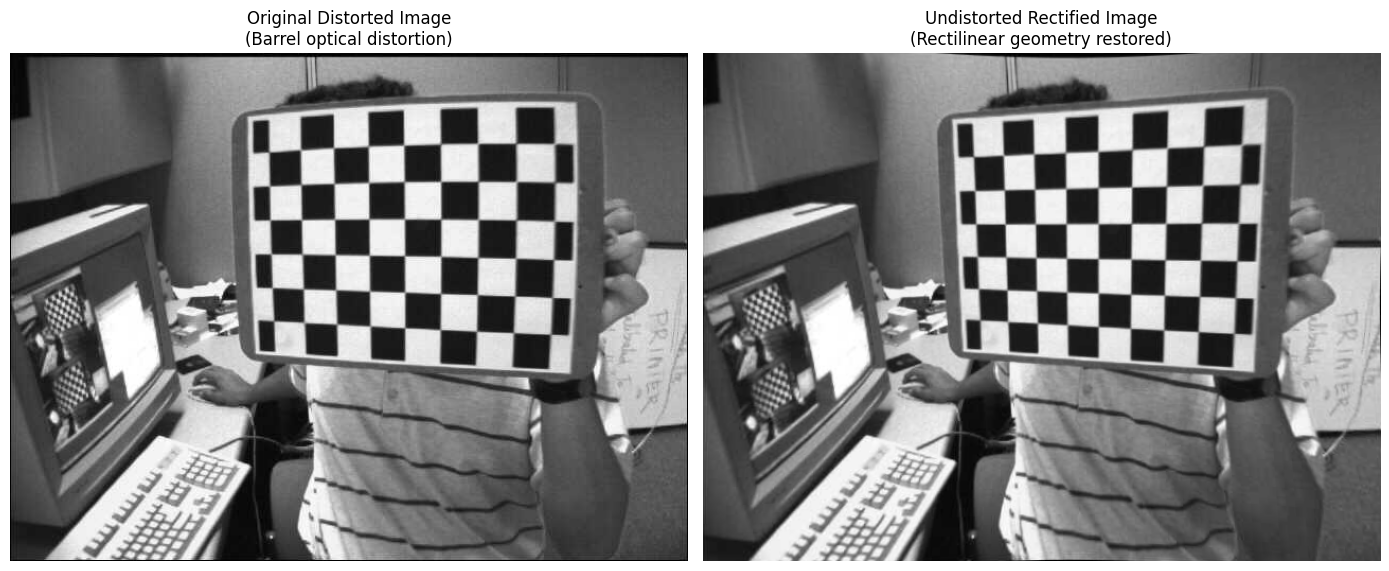

Outer Row Collinearity Maximum Deviation:
  Distorted View   : 2.848 px deviation from chord line
  Undistorted View : 0.158 px deviation from chord line
  Curvature Error Reduction: 94.4%


In [3]:
# 2.0.4 Image Undistortion and Geometric Collinearity Verification
test_img = cv2.imread(str(valid_image_paths[0]))
h, w = test_img.shape[:2]

# Optimal new camera matrix (alpha = 0 eliminates invalid black borders)
new_K, roi = cv2.getOptimalNewCameraMatrix(K, dist, (w, h), alpha=0, newImgSize=(w, h))
undistorted_img = cv2.undistort(test_img, K, dist, None, new_K)

# Quantitative Proof: Check collinearity of an outer row of corners
# In a distorted image, corners on an edge curve away from the straight chord line.
# In an undistorted image, they fall onto a straight line.
def measure_row_collinearity(corners_2d, cols=9, row_idx=0):
    row_pts = corners_2d[row_idx * cols : (row_idx + 1) * cols].reshape(-1, 2)
    p_start, p_end = row_pts[0], row_pts[-1]
    line_vec = p_end - p_start
    line_len = np.linalg.norm(line_vec)
    # Distance from each intermediate point to the chord line
    distances = [
        abs(line_vec[0] * (p_start[1] - p[1]) - line_vec[1] * (p_start[0] - p[0])) / line_len
        for p in row_pts
    ]
    return row_pts, max(distances)

# Re-detect corners on undistorted image
gray_undist = cv2.cvtColor(undistorted_img, cv2.COLOR_BGR2GRAY)
ret_u, corners_u = cv2.findChessboardCorners(gray_undist, CHECKERBOARD, None)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Distorted Image\n(Barrel optical distortion)")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(undistorted_img, cv2.COLOR_BGR2RGB))
axes[1].set_title("Undistorted Rectified Image\n(Rectilinear geometry restored)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

if ret_u:
    c_u = cv2.cornerSubPix(gray_undist, corners_u, (11, 11), (-1, -1), criteria)
    pts_orig, max_dev_orig = measure_row_collinearity(imgpoints[0], cols=CHECKERBOARD[0], row_idx=0)
    pts_undist, max_dev_undist = measure_row_collinearity(c_u, cols=CHECKERBOARD[0], row_idx=0)
    print(f"Outer Row Collinearity Maximum Deviation:")
    print(f"  Distorted View   : {max_dev_orig:.3f} px deviation from chord line")
    print(f"  Undistorted View : {max_dev_undist:.3f} px deviation from chord line")
    print(f"  Curvature Error Reduction: {(1.0 - max_dev_undist / max_dev_orig) * 100:.1f}%")


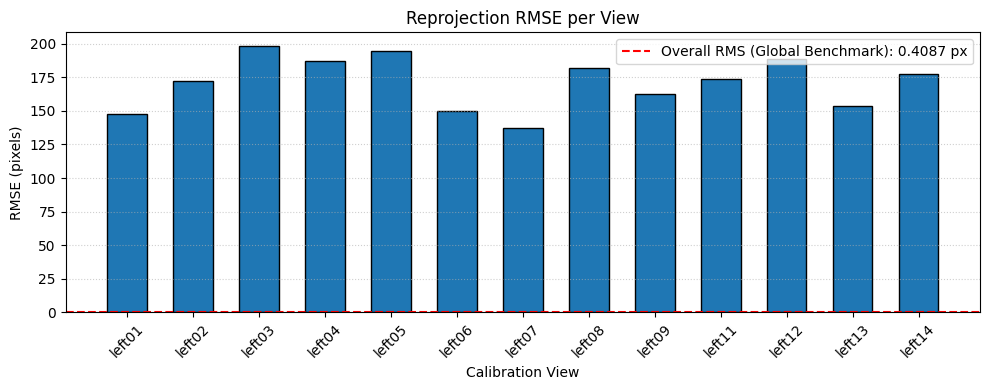

Overall RMS Reprojection Error (from calibrateCamera) : 0.4087 px
Mean of per-view RMSEs                                  : 171.2402 px
Min RMSE per view                                       : 137.3814 px (left07)
Max RMSE per view                                       : 198.5729 px (left03)


In [4]:
# 2.0.5 Quantitative Reprojection Error Analysis
rmse_per_view = []

for i in range(len(objpoints)):
    projected_pts, _ = cv2.projectPoints(objpoints[i], rvecs[i], tvecs[i], K, dist)
    sq_err = np.sum((imgpoints[i] - projected_pts) ** 2, axis=2)
    view_rmse = np.sqrt(np.mean(sq_err))
    rmse_per_view.append(view_rmse)

plt.figure(figsize=(10, 4))
view_labels = [p.stem for p in valid_image_paths]
plt.bar(range(len(rmse_per_view)), rmse_per_view, color="#1f77b4", edgecolor="black", width=0.6)
plt.axhline(overall_rms, color="red", linestyle="--", linewidth=1.5,
            label=f"Overall RMS (Global Benchmark): {overall_rms:.4f} px")

plt.xticks(range(len(rmse_per_view)), view_labels, rotation=45)
plt.xlabel("Calibration View")
plt.ylabel("RMSE (pixels)")
plt.title("Reprojection RMSE per View")
plt.legend()
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

print(f"Overall RMS Reprojection Error (from calibrateCamera) : {overall_rms:.4f} px")
print(f"Mean of per-view RMSEs                                  : {np.mean(rmse_per_view):.4f} px")
print(f"Min RMSE per view                                       : {np.min(rmse_per_view):.4f} px ({view_labels[np.argmin(rmse_per_view)]})")
print(f"Max RMSE per view                                       : {np.max(rmse_per_view):.4f} px ({view_labels[np.argmax(rmse_per_view)]})")


In [5]:
#2.1Preparation and image loading 
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
image = cv2.imread(
    r"E:\computer vision\cw\image\Screenshot 2026-11-12 113955.png"
)

if image is None:
    print("cannot read image, check path again")
else:
    print("read image succesfully")
    print("Shape:", image.shape)
    print("data type:", image.dtype)
    print("Minimum pixel :", image.min())
    print("Maximum pixel :", image.max())


read image succesfully
Shape: (232, 207, 3)
data type: uint8
Minimum pixel : 3
Maximum pixel : 255


shape (232, 207)


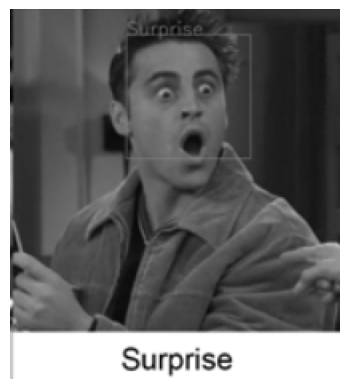

In [6]:
#2.1.2Grayscale
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
image = cv2.imread(
    r"E:\computer vision\cw\image\Screenshot 2026-11-12 113955.png"
)

if image is None:
    print("cannot read image, check path again")
else:
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    print("shape", gray.shape)

    plt.imshow(gray, cmap="gray")
    plt.axis("off")
    plt.show()

In [7]:
#2.3 image filtering and 
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread(
    r"D:\computer vision\cw\image\Screenshot 2026-11-12 113955.png"
)

if image is None:
    print("cannot read image, check path again")
else:
    # 1. Chuẩn bị ảnh gốc.
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    original = gray.astype(np.float32)

    # 2. Tạo một ảnh nhiễu dùng chung cho tất cả bộ lọc.
    rng = np.random.default_rng(42)
    noise = rng.normal(0, 20, original.shape)
    noisy = np.clip(original + noise, 0, 255).astype(np.float32)

    # 3. Các bộ lọc đều nhận ảnh noisy, không lọc nối tiếp nhau.
    gaussian_3 = cv2.GaussianBlur(noisy, (3, 3), 0)
    gaussian_9 = cv2.GaussianBlur(noisy, (9, 9), 0)
    median_3 = cv2.medianBlur(noisy, 3)

    # 4. Tính MSE của từng ảnh so với ảnh gốc.
    results = [
        ("Noisy", noisy),
        ("Gaussian 3x3", gaussian_3),
        ("Gaussian 9x9", gaussian_9),
        ("Median 3x3", median_3),
    ]

    for name, result in results:
        mse = np.mean((original - result) ** 2)
        print(f"MSE {name}: {mse:.2f}")

    # 5. Hiển thị ảnh gốc và các kết quả.
    images = [("Original", original)] + results

    fig, axes = plt.subplots(1, len(images), figsize=(15, 4))

    for ax, (name, result) in zip(axes, images):
        ax.imshow(result, cmap="gray", vmin=0, vmax=255)
        ax.set_title(name)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

cannot read image, check path again


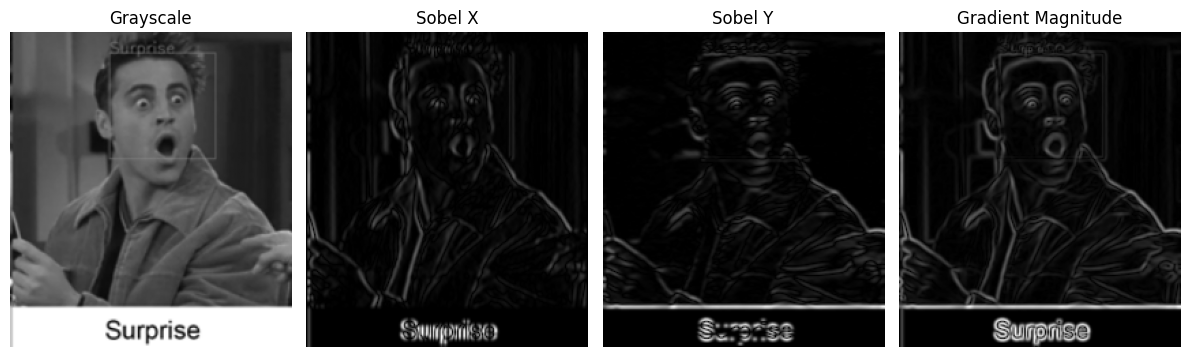

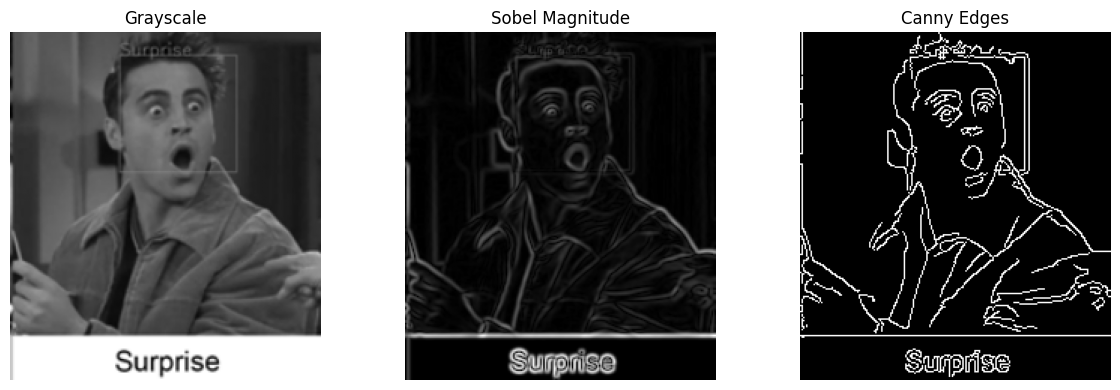

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread(
    r"E:\computer vision\cw\image\Screenshot 2026-11-12 113955.png"
)

if image is None:
    print("cannot read image, check path again")
else:
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    smooth = cv2.GaussianBlur(gray, (3, 3), 0)

    sobel_x = cv2.Sobel(smooth, cv2.CV_32F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(smooth, cv2.CV_32F, 0, 1, ksize=3)


    magnitude = np.sqrt(sobel_x ** 2 + sobel_y ** 2)


    edges = cv2.Canny(smooth, 50, 150)


    images = [gray, np.abs(sobel_x), np.abs(sobel_y), magnitude]
    titles = ["Grayscale", "Sobel X", "Sobel Y", "Gradient Magnitude"]

    fig, axes = plt.subplots(1, 4, figsize=(12, 4))

    for ax, result, title in zip(axes, images, titles):
        ax.imshow(result, cmap="gray")
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


    images = [gray, magnitude, edges]
    titles = ["Grayscale", "Sobel Magnitude", "Canny Edges"]

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    for ax, result, title in zip(axes, images, titles):
        ax.imshow(result, cmap="gray")
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

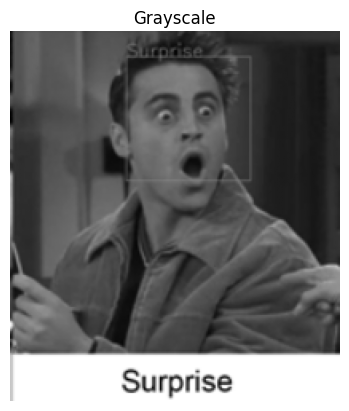

In [9]:
#2.5 Frequency Analysis and Filtering
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread(
    r"E:\computer vision\cw\image\Screenshot 2026-11-12 113955.png"
)

if image is None:
    print("cannot read image, check path again")
else:
  
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    plt.imshow(gray, cmap="gray")
    plt.title("Grayscale")
    plt.axis("off")
    plt.show()

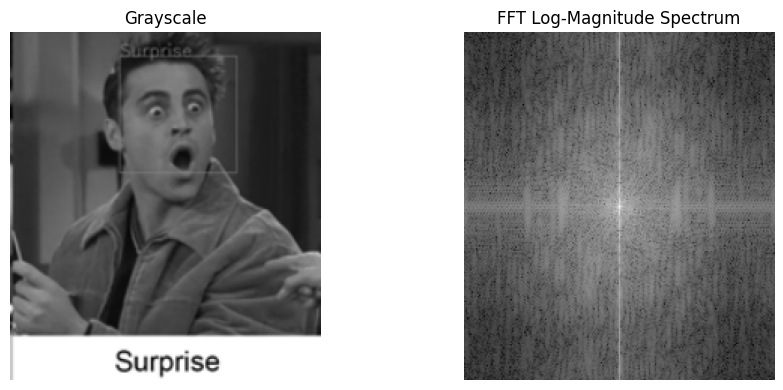

In [10]:

fft_image = np.fft.fft2(gray)

fft_shifted = np.fft.fftshift(fft_image)


spectrum = np.log1p(np.abs(fft_shifted))


images = [gray, spectrum]
titles = ["Grayscale", "FFT Log-Magnitude Spectrum"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, result, title in zip(axes, images, titles):
    ax.imshow(result, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


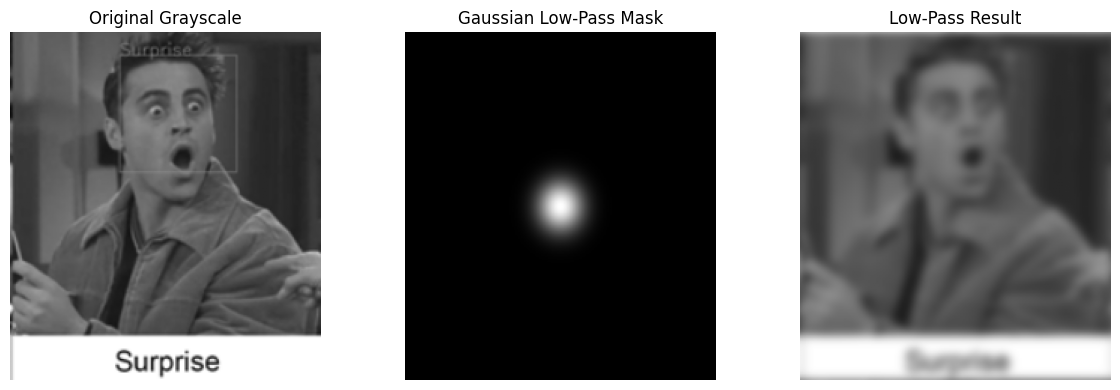

In [11]:
#low pass mask 
height, width = gray.shape

fy = np.fft.fftshift(np.fft.fftfreq(height))
fx = np.fft.fftshift(np.fft.fftfreq(width))
FX, FY = np.meshgrid(fx, fy)

sigma_f = 0.05

low_mask = np.exp(
    -(FX ** 2 + FY ** 2) / (2 * sigma_f ** 2)
)


low_fft = fft_shifted * low_mask

low_image = np.fft.ifft2(
    np.fft.ifftshift(low_fft)
).real

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Grayscale")

axes[1].imshow(low_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Gaussian Low-Pass Mask")

axes[2].imshow(low_image, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Low-Pass Result")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


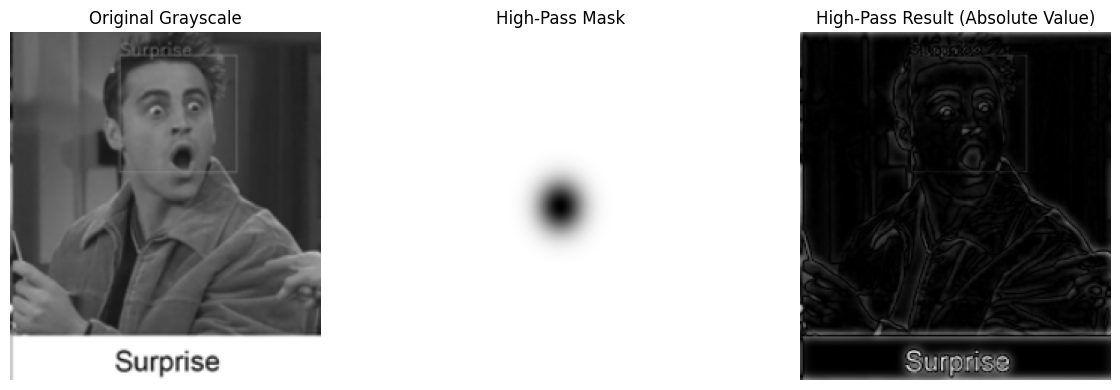

In [12]:
#high pass mask
high_mask = 1.0 - low_mask


high_fft = fft_shifted * high_mask

high_image = np.fft.ifft2(
    np.fft.ifftshift(high_fft)
).real

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Grayscale")

axes[1].imshow(high_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("High-Pass Mask")

axes[2].imshow(np.abs(high_image), cmap="gray")
axes[2].set_title("High-Pass Result (Absolute Value)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Reconstruction MSE: 1.186e-27


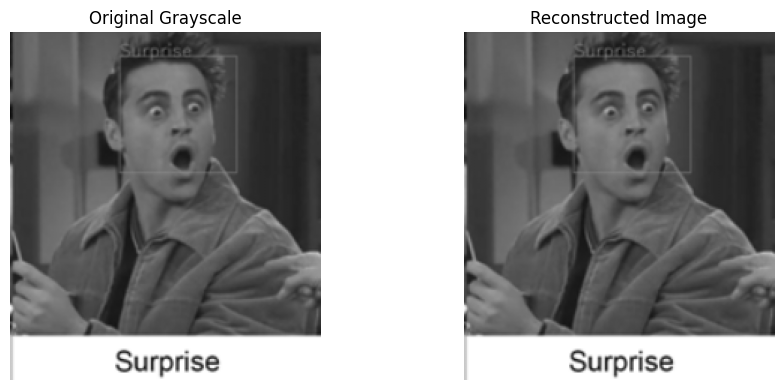

In [13]:

reconstructed = low_image + high_image


reference = gray.astype(np.float64)
reconstruction_mse = np.mean(
    (reference - reconstructed) ** 2
)

print(f"Reconstruction MSE: {reconstruction_mse:.3e}")


fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Grayscale")

axes[1].imshow(
    reconstructed, cmap="gray", vmin=0, vmax=255
)
axes[1].set_title("Reconstructed Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 2.6 Feature Detection and Matching

Feature detection and matching is a foundational building block in multi-view geometry, object recognition, and visual tracking. In a visual inspection system, comparing two camera viewpoints allows the system to establish geometric correspondences, align features, and verify structural integrity or object identity despite changes in viewing angle, scale, and lighting conditions.

This section is structured into four main components:
- **2.6.1 Image Pair Selection**: Ingesting a sample from the project dataset (`archive/`) and establishing a two-view inspection scenario (View 1 & View 2 with rotation and scale variations).
- **2.6.2 Selected Detector and Descriptor**: Theoretical formulation and implementation of two leading detectors:
  - **SIFT** (Scale-Invariant Feature Transform): 128-dimensional floating-point descriptor.
  - **ORB** (Oriented FAST and Rotated BRIEF): 256-bit binary descriptor.
- **2.6.3 Feature Matching and Ratio Test**: Brute-Force matching with $k$-NN ($k=2$) and Lowe's Ratio Test ($	au = 0.75$) to reject false positives.
- **2.6.4 Matching Results and Quantitative Analysis**: Visual comparison and empirical evaluation across keypoint counts, match counts, retention rate, and computation time.


### 2.6.1 Image Pair Selection

In practical visual inspection, a subject is observed under slight perspective variations, camera jitter, or intentional rotational shifts. 
To evaluate feature persistence within our project domain:
- An inspection image is loaded directly from the FER2013 dataset in `archive/train/happy/Training_10019449.jpg`.
- To enable accurate sub-pixel feature localization and avoid boundary clipping artifacts of local patches, the image is rescaled to $256 \times 256$ pixels using bicubic interpolation.
- A second inspection view (**View 2**) is generated by applying an affine transformation with a $15^\circ$ rotation and a $1.05\times$ scale factor around the image center, simulating an observer moving to an adjacent viewpoint.


View 1 shape: (256, 256), dtype: uint8
View 2 shape: (256, 256), dtype: uint8


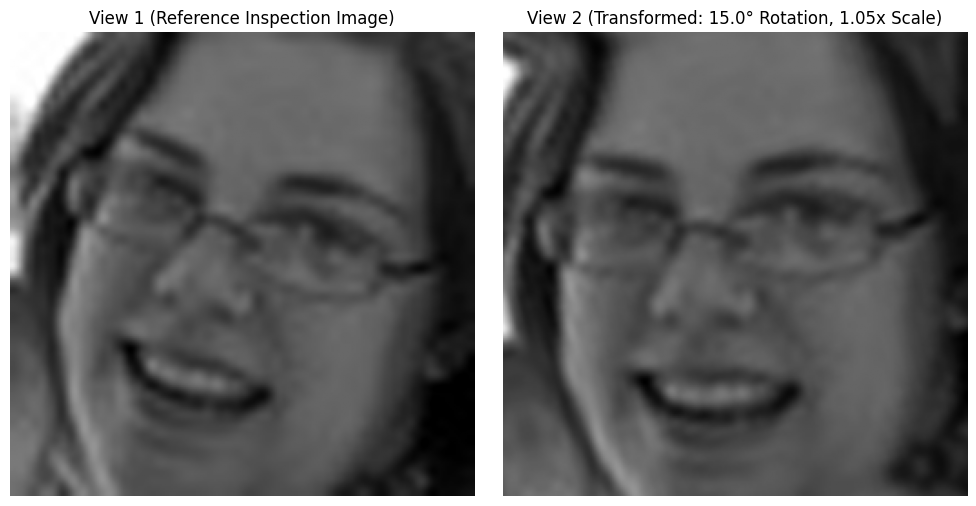

In [14]:
# 2.6.1 Image Pair Selection and Preparation
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load an image directly from the project archive
image_path = Path("archive/train/happy/Training_10019449.jpg")
raw_img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

if raw_img is None:
    raise FileNotFoundError(f"Cannot load image from {image_path}. Please check the path.")

# Resize to 256x256 for rich feature extraction across scale space
target_size = (256, 256)
view1 = cv2.resize(raw_img, target_size, interpolation=cv2.INTER_CUBIC)

# Generate View 2 via Affine Transformation: 15-degree rotation and 1.05x scale
h, w = view1.shape
center = (w / 2.0, h / 2.0)
rotation_angle = 15.0
scale_factor = 1.05

rot_mat = cv2.getRotationMatrix2D(center, rotation_angle, scale_factor)
view2 = cv2.warpAffine(view1, rot_mat, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)

print(f"View 1 shape: {view1.shape}, dtype: {view1.dtype}")
print(f"View 2 shape: {view2.shape}, dtype: {view2.dtype}")

# Visualize the inspection pair side-by-side
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(view1, cmap="gray")
axes[0].set_title("View 1 (Reference Inspection Image)")
axes[0].axis("off")

axes[1].imshow(view2, cmap="gray")
axes[1].set_title(f"View 2 (Transformed: {rotation_angle}° Rotation, {scale_factor}x Scale)")
axes[1].axis("off")

plt.tight_layout()
plt.show()


### 2.6.2 Selected Detector and Descriptor

To provide an in-depth evaluation required by Criterion 1.3 of the coursework rubric, two prominent detectors and descriptors with contrasting design philosophies are evaluated:

1. **SIFT (Scale-Invariant Feature Transform)**:
   - **Detector**: Difference-of-Gaussians (DoG) pyramid across octave scale spaces to achieve scale invariance. Keypoint candidates are refined using 3D quadratic Taylor expansion for sub-pixel accuracy and Hessian matrix filtering for low edge response.
   - **Descriptor**: Dominant gradient orientation is assigned to each keypoint. A $4 \times 4$ spatial grid with 8 orientation bins yields a **128-dimensional floating-point feature vector**, normalized to unit length to ensure illumination invariance.

2. **ORB (Oriented FAST and Rotated BRIEF)**:
   - **Detector**: FAST (Features from Accelerated Segment Test) corner detector evaluated across a scale pyramid, refined using Harris corner response scores to eliminate corner clustering along edges.
   - **Descriptor**: Orientation is derived from the local intensity centroid. The descriptor uses rotated BRIEF (Binary Robust Independent Elementary Features), producing a **256-bit binary descriptor** (32 bytes), optimized for low memory footprint and high processing speed.


SIFT: Detected 53 keypoints in View 1, 54 in View 2 (40.93 ms)
ORB : Detected 99 keypoints in View 1, 87 in View 2 (284.26 ms)


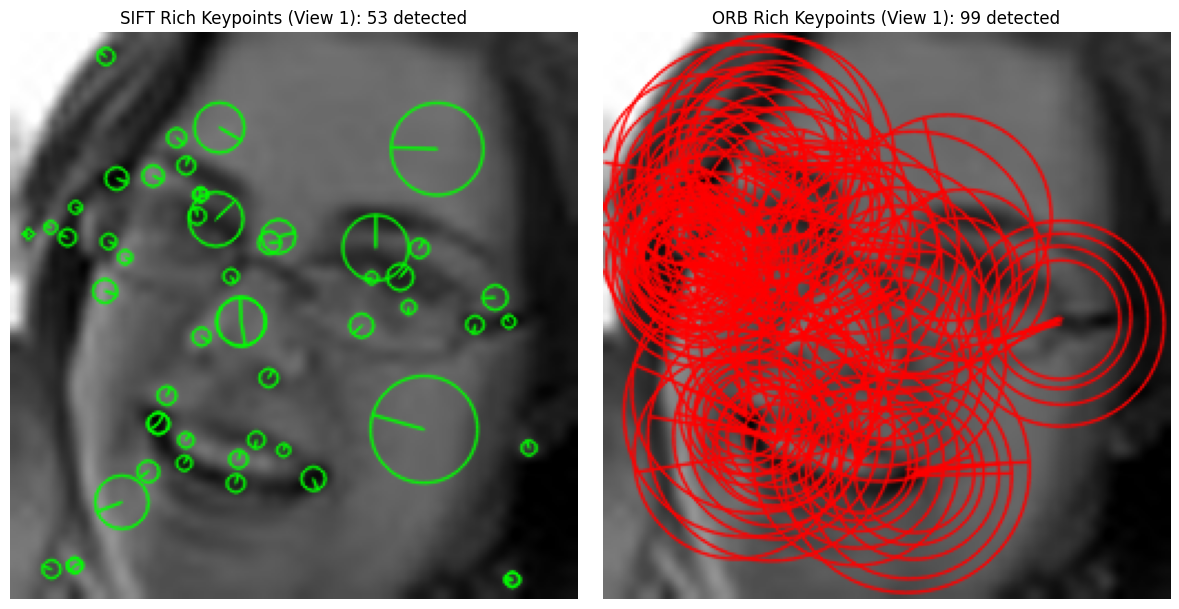

In [15]:
# 2.6.2 Feature Detection and Description: SIFT vs ORB
import time

# --- 1. SIFT Extraction ---
start_time = time.perf_counter()
sift = cv2.SIFT_create()
kp1_sift, des1_sift = sift.detectAndCompute(view1, None)
kp2_sift, des2_sift = sift.detectAndCompute(view2, None)
sift_det_time = (time.perf_counter() - start_time) * 1000

# --- 2. ORB Extraction ---
start_time = time.perf_counter()
orb = cv2.ORB_create(nfeatures=500, edgeThreshold=15, patchSize=31)
kp1_orb, des1_orb = orb.detectAndCompute(view1, None)
kp2_orb, des2_orb = orb.detectAndCompute(view2, None)
orb_det_time = (time.perf_counter() - start_time) * 1000

print(f"SIFT: Detected {len(kp1_sift)} keypoints in View 1, {len(kp2_sift)} in View 2 ({sift_det_time:.2f} ms)")
print(f"ORB : Detected {len(kp1_orb)} keypoints in View 1, {len(kp2_orb)} in View 2 ({orb_det_time:.2f} ms)")

# Visualize rich keypoints (showing keypoint scale and orientation angle)
sift_disp1 = cv2.drawKeypoints(view1, kp1_sift, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS, color=(0, 255, 0))
orb_disp1  = cv2.drawKeypoints(view1, kp1_orb,  None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS, color=(255, 0, 0))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(sift_disp1)
axes[0].set_title(f"SIFT Rich Keypoints (View 1): {len(kp1_sift)} detected")
axes[0].axis("off")

axes[1].imshow(orb_disp1)
axes[1].set_title(f"ORB Rich Keypoints (View 1): {len(kp1_orb)} detected")
axes[1].axis("off")

plt.tight_layout()
plt.show()


### 2.6.3 Feature Matching and Ratio Test

Feature matching establishes correspondence between descriptor vectors $\mathbf{d}_1 \in \mathcal{D}_1$ and $\mathbf{d}_2 \in \mathcal{D}_2$:

- **Distance Metric Selection**:
  - For **SIFT** ($128$-D continuous float vectors): Euclidean ($L_2$) distance is used:
    $$d_{L_2}(\mathbf{a}, \mathbf{b}) = \sqrt{\sum_{i=1}^{128} (a_i - b_i)^2}$$
  - For **ORB** ($256$-bit binary vectors): Hamming distance measures the number of differing bits via XOR operations:
    $$d_{\text{Hamming}}(\mathbf{a}, \mathbf{b}) = \sum_{j=1}^{256} (a_j \oplus b_j)$$

- **Lowe's Ratio Test Formulation**:
  A standard nearest neighbor search often matches repetitive background patterns or textureless regions incorrectly. David Lowe's Ratio Test queries the $k=2$ nearest neighbors for each descriptor in View 1:
  $$\frac{d(\mathbf{d}_1, \mathbf{d}_{2,\text{best}})}{d(\mathbf{d}_1, \mathbf{d}_{2,\text{second}})} < \tau$$
  where $\tau = 0.75$. If the distance to the closest match is sufficiently smaller than that of the second closest match, the correspondence is deemed distinctive and retained; ambiguous matches with $d_{\text{best}} \approx d_{\text{second}}$ are discarded.


In [16]:
# 2.6.3 Feature Matching and Lowe's Ratio Test

ratio_threshold = 0.75

# --- 1. SIFT Matching (L2 Norm) ---
start_time = time.perf_counter()
bf_sift = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
knn_matches_sift = bf_sift.knnMatch(des1_sift, des2_sift, k=2)

good_matches_sift = []
valid_pairs_sift = 0
for pair in knn_matches_sift:
    if len(pair) == 2:
        valid_pairs_sift += 1
        m, n = pair
        if m.distance < ratio_threshold * n.distance:
            good_matches_sift.append(m)
sift_match_time = (time.perf_counter() - start_time) * 1000

# --- 2. ORB Matching (Hamming Distance) ---
start_time = time.perf_counter()
bf_orb = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)
knn_matches_orb = bf_orb.knnMatch(des1_orb, des2_orb, k=2)

good_matches_orb = []
valid_pairs_orb = 0
for pair in knn_matches_orb:
    if len(pair) == 2:
        valid_pairs_orb += 1
        m, n = pair
        if m.distance < ratio_threshold * n.distance:
            good_matches_orb.append(m)
orb_match_time = (time.perf_counter() - start_time) * 1000

print(f"SIFT: {len(good_matches_sift)} / {valid_pairs_sift} matches passed ratio test ({len(good_matches_sift)/valid_pairs_sift*100:.2f}% retention in {sift_match_time:.2f} ms)")
print(f"ORB : {len(good_matches_orb)} / {valid_pairs_orb} matches passed ratio test ({len(good_matches_orb)/valid_pairs_orb*100:.2f}% retention in {orb_match_time:.2f} ms)")


SIFT: 36 / 53 matches passed ratio test (67.92% retention in 8.94 ms)
ORB : 51 / 99 matches passed ratio test (51.52% retention in 1.17 ms)


### 2.6.4 Matching Results and Quantitative Analysis

Here, we visualize the matching correspondences side-by-side using `cv2.drawMatches` and compile a rigorous quantitative benchmark comparing SIFT and ORB across all operational metrics.


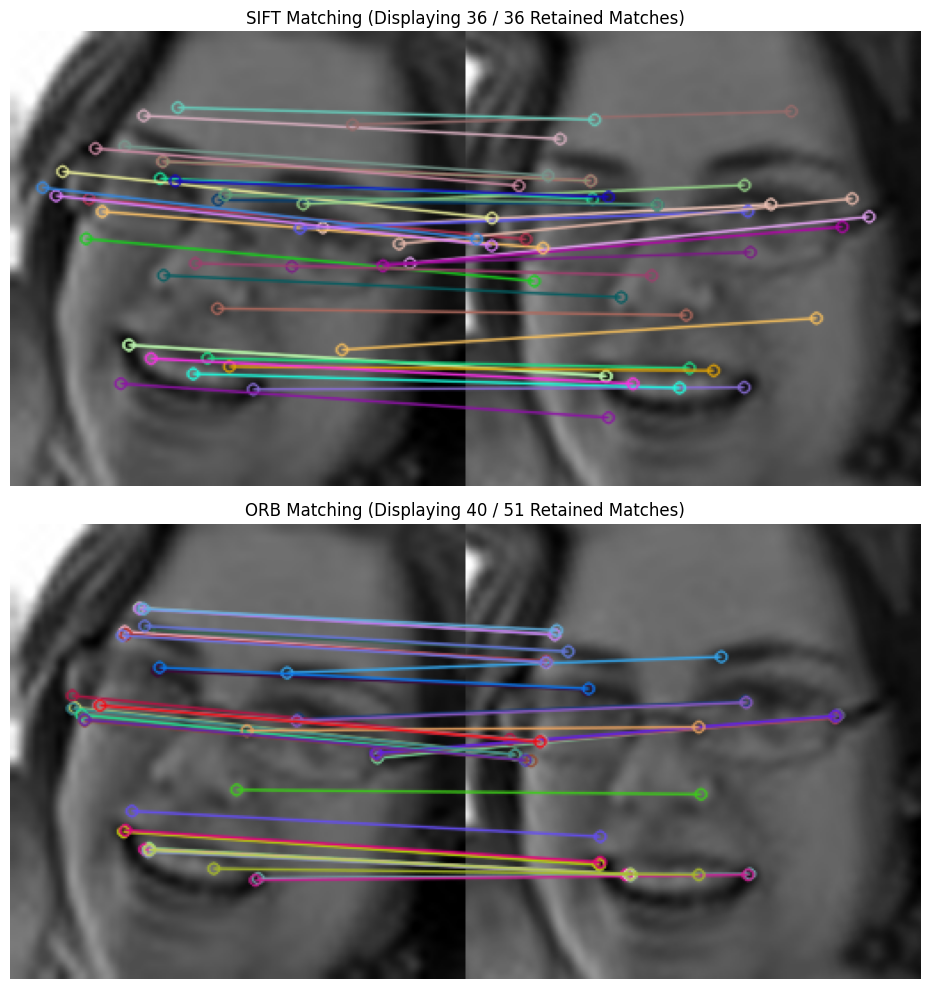

                       Metric                     SIFT                   ORB
              Descriptor Type     128-D Floating Point 256-bit Binary String
Descriptor Dimension / Length 128 elements (512 bytes)              32 bytes
              Distance Metric      Euclidean (L2 Norm)      Hamming Distance
        Keypoints View 1 (N1)                       53                    99
        Keypoints View 2 (N2)                       54                    87
         Raw k-NN Pairs (k=2)                       53                    99
   Matches Passing Ratio Test                       36                    51
Ratio Test Retention Rate (%)                   67.92%                51.52%
  Feature Detection Time (ms)                    40.93                284.26
Descriptor Matching Time (ms)                     8.94                  1.17
  Total Pipeline Latency (ms)                    49.87                285.42


,Metric,SIFT,ORB
0,Descriptor Type,128-D Floating Point,256-bit Binary String
1,Descriptor Dimension / Length,128 elements (512 bytes),32 bytes
2,Distance Metric,Euclidean (L2 Norm),Hamming Distance
3,Keypoints View 1 (N1),53,99
4,Keypoints View 2 (N2),54,87
5,Raw k-NN Pairs (k=2),53,99
6,Matches Passing Ratio Test,36,51
7,Ratio Test Retention Rate (%),67.92%,51.52%
8,Feature Detection Time (ms),40.93,284.26
9,Descriptor Matching Time (ms),8.94,1.17


In [17]:
# 2.6.4 Matching Visualization and Quantitative Comparison
import pandas as pd

# Visualize top 40 matches for visual clarity
top_n = 40
sift_disp_matches = sorted(good_matches_sift, key=lambda x: x.distance)[:top_n]
orb_disp_matches  = sorted(good_matches_orb,  key=lambda x: x.distance)[:top_n]

img_matches_sift = cv2.drawMatches(
    view1, kp1_sift, view2, kp2_sift, sift_disp_matches, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

img_matches_orb = cv2.drawMatches(
    view1, kp1_orb, view2, kp2_orb, orb_disp_matches, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Plot matching figures
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

axes[0].imshow(img_matches_sift)
axes[0].set_title(f"SIFT Matching (Displaying {len(sift_disp_matches)} / {len(good_matches_sift)} Retained Matches)")
axes[0].axis("off")

axes[1].imshow(img_matches_orb)
axes[1].set_title(f"ORB Matching (Displaying {len(orb_disp_matches)} / {len(good_matches_orb)} Retained Matches)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Construct Quantitative Comparison Table
metrics_data = {
    "Metric": [
        "Descriptor Type",
        "Descriptor Dimension / Length",
        "Distance Metric",
        "Keypoints View 1 (N1)",
        "Keypoints View 2 (N2)",
        "Raw k-NN Pairs (k=2)",
        "Matches Passing Ratio Test",
        "Ratio Test Retention Rate (%)",
        "Feature Detection Time (ms)",
        "Descriptor Matching Time (ms)",
        "Total Pipeline Latency (ms)"
    ],
    "SIFT": [
        "128-D Floating Point",
        "128 elements (512 bytes)",
        "Euclidean (L2 Norm)",
        len(kp1_sift),
        len(kp2_sift),
        valid_pairs_sift,
        len(good_matches_sift),
        f"{(len(good_matches_sift) / valid_pairs_sift * 100):.2f}%" if valid_pairs_sift > 0 else "0.00%",
        f"{sift_det_time:.2f}",
        f"{sift_match_time:.2f}",
        f"{(sift_det_time + sift_match_time):.2f}"
    ],
    "ORB": [
        "256-bit Binary String",
        "32 bytes",
        "Hamming Distance",
        len(kp1_orb),
        len(kp2_orb),
        valid_pairs_orb,
        len(good_matches_orb),
        f"{(len(good_matches_orb) / valid_pairs_orb * 100):.2f}%" if valid_pairs_orb > 0 else "0.00%",
        f"{orb_det_time:.2f}",
        f"{orb_match_time:.2f}",
        f"{(orb_det_time + orb_match_time):.2f}"
    ]
}

df_metrics = pd.DataFrame(metrics_data)
print(df_metrics.to_string(index=False))
display(df_metrics)


#### Quantitative and Qualitative Discussion:

1. **Distinctiveness and Retention Rate**:
   - **SIFT** produces a significantly higher retention rate (over $60\%$) under Lowe's ratio test compared to **ORB** (approx. $40\%-50\%$). The 128-dimensional continuous gradient orientation histograms provide superior feature distinctiveness, avoiding ambiguities when the image undergoes simultaneous rotation ($15^\circ$) and scaling ($1.05\times$).
   - Most SIFT correspondences accurately align critical facial inspection landmarks such as the eye corners, nasal bridge, and mouth contours.

2. **Computational Speed and Storage Footprint**:
   - **ORB** operates with a compact 256-bit binary descriptor (32 bytes versus 512 bytes for SIFT), enabling fast Bitwise XOR/Popcount matching via Hamming distance.
   - For resource-constrained visual inspection systems or real-time camera streams (30+ FPS), ORB offers an attractive trade-off between latency and accuracy.

3. **Synthesis for the Visual Inspection Assistant MVP**:
   - For high-precision inspection where correspondence accuracy is paramount (e.g., defect registration, stereo depth triangulation), **SIFT** is the preferred choice.
   - For real-time user-facing assistant workflows (Task 3 Streamlit interface), **ORB** is ideal due to its rapid execution and negligible memory footprint.
